In [1]:
import pandas as pd
import numpy as np
import yfinance as yf

In [2]:
stk_data = yf.download("TATACONSUM.NS", start = "2022-06-01", end = "2023-01-05")

[*********************100%***********************]  1 of 1 completed


In [3]:
# Check whether the column names have multiple levels. Ex:("Close", "TATACONSUM.NS")
if stk_data.columns.nlevels > 1:
    stk_data.columns = stk_data.columns.get_level_values(0)  # Keep only the first level: Close, High, Low, Open, Volume.

In [4]:
stk_data = stk_data[["Open","High","Low","Close"]]

In [5]:
stk_data

Price,Open,High,Low,Close
Date,,,,
2022-06-01,729.168098,748.836448,727.009377,730.223450
2022-06-02,726.289785,729.647796,716.695468,727.489075
2022-06-03,729.168185,739.721935,721.540690,723.315674
2022-06-06,726.049942,738.762412,715.064437,732.670044
2022-06-07,731.086960,731.086960,715.831973,725.906006
...,...,...,...,...
2022-12-29,753.343023,753.343023,737.966678,750.538513
2022-12-30,752.375928,756.534292,739.804093,741.689880
2023-01-02,744.542778,745.606525,733.131373,737.193054


In [6]:
column = "Close"

In [7]:
from sklearn.preprocessing import MinMaxScaler
Ms = MinMaxScaler()
data1 = Ms.fit_transform(stk_data[[column]])
print("Len:", data1.shape)

Len: (150, 1)


In [8]:
len(data1)

150

In [9]:
training_size = round(len(data1 ) * 0.80)
print(training_size)

X_train = data1[:training_size]
X_test = data1[training_size:]
print("X_train length:", X_train.shape)
print("X_test length:", X_test.shape)

y_train = data1[:training_size]
y_test = data1[training_size:]
print("y_train length:", y_train.shape)
print("y_test length:", y_test.shape)

120
X_train length: (120, 1)
X_test length: (30, 1)
y_train length: (120, 1)
y_test length: (30, 1)


In [11]:
from statsmodels.tsa.ar_model import AutoReg
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

for lag in [5,10,15,20,30]:

    model = AutoReg(X_train, lags=lag)
    model_fit = model.fit()

    y_pred = model_fit.predict(
        start=len(X_train),
        end=len(data1)-1
    )

    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    print(f"Lag={lag}")
    print("RMSE =", rmse)
    print("R2 =", r2)
    print("----------------")

Lag=5
RMSE = 0.18141118376377724
R2 = -1.5470868132495066
----------------
Lag=10
RMSE = 0.1706502818638297
R2 = -1.2538740992747814
----------------
Lag=15
RMSE = 0.15423422676954476
R2 = -0.8410990504569305
----------------
Lag=20
RMSE = 0.15324467766600072
R2 = -0.8175502761378628
----------------
Lag=30
RMSE = 0.13690935886163422
R2 = -0.45071434783191555
----------------


In [13]:
# AR Model
from statsmodels.tsa.ar_model import AutoReg

model = AutoReg(X_train, lags=10)
model_fit = model.fit()

y_pred = model_fit.predict(
    start=len(X_train),
    end=len(data1)-1
)

In [14]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("RMSE:", rmse)
print("R2:", r2)

RMSE: 0.1706502818638297
R2: -1.2538740992747814


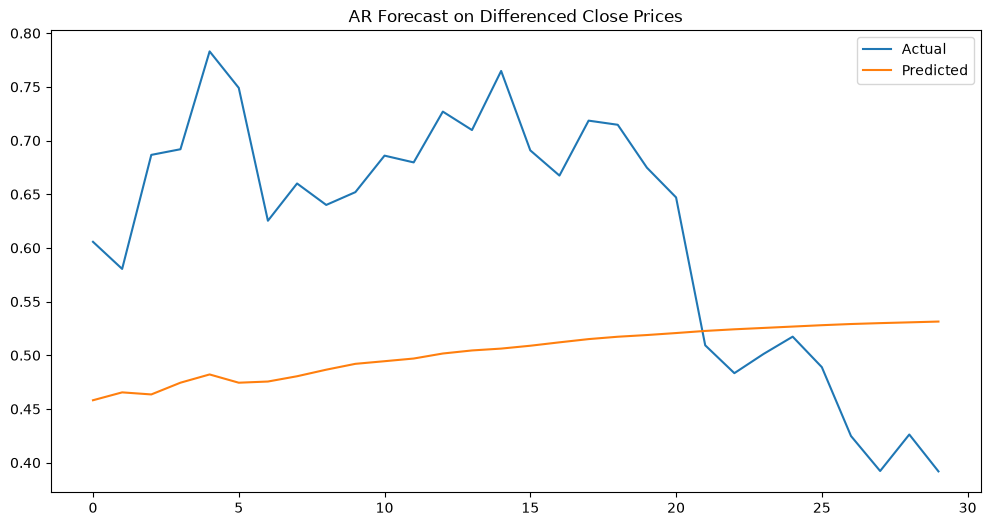

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(y_test, label="Actual")
plt.plot(y_pred, label="Predicted")
plt.legend()
plt.title("AR Forecast on Differenced Close Prices")
plt.show()

In [ ]:
#Chatgpt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error
from statsmodels.tsa.ar_model import AutoReg

# data1 must contain one time series, ordered chronologically.
series = np.asarray(data1).squeeze()
if series.ndim != 1:
    raise ValueError("data1 must contain exactly one time series.")

training_size = round(len(series) * 0.80)
train = series[:training_size]
test = series[training_size:]

print("Train shape:", train.shape)
print("Test shape:", test.shape)

results = []

for lag in [1, 2, 3, 4]:
    for trend in ["n", "t", "c", "ct"]:
        model_fit = AutoReg(train, lags=lag, trend=trend).fit()

        predictions = model_fit.predict(
            start=len(train),
            end=len(series) - 1
        )

        rmse = np.sqrt(mean_squared_error(test, predictions))

        # MAPE is undefined when any actual value is zero.
        mape = (
            np.mean(np.abs((test - predictions) / test)) * 100
            if np.all(test != 0)
            else np.nan
        )

        results.append({
            "lag": lag,
            "trend": trend,
            "RMSE": rmse,
            "MAPE (%)": mape,
        })

results = pd.DataFrame(results).sort_values("RMSE")
print(results.to_string(index=False))